# AI 기초 10주차 실습 — 이론을 코드로 확인하기 (RNN · BPTT · LSTM, Keras)

이론 강의에서 배운 내용이 실제 코드에서도 그대로 일어나는지 직접 확인합니다.

| 실습 | 확인할 이론 | 이론 슬라이드 |
| --- | --- | --- |
| 1. RNN 셀 직접 계산 | hₜ = tanh(Wₓxₜ + Wₕhₜ₋₁ + b), 손 계산 결과 | 9, 12 |
| 2. 파라미터 공유 | 길이가 달라도 파라미터 수는 같다, LSTM 4배·GRU 약 3배 | 11, 24 |
| 3. 기울기 측정 | BPTT의 반복 곱셈 → 기울기 소실 | 13–16 |
| 4. 첫 단어 기억하기 | RNN은 장기 의존성에 실패, LSTM은 망각 게이트로 해결 | 17, 22 |

- 코랩 런타임은 **CPU로 충분**합니다. 전체 실행 시간은 2~3분 정도입니다.
- 위에서부터 차례로 `Shift + Enter`로 실행하세요.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"       # TensorFlow 안내 메시지 줄이기

import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

keras.utils.set_random_seed(0)                 # 누가 실행해도 같은 결과가 나오도록 고정
print("TensorFlow", tf.__version__, "/ Keras", keras.__version__)

I0000 00:00:1793951365.937567     699 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793951367.383336     699 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 / Keras 3.15.1


## 실습 1. RNN 셀을 직접 계산해 보기 (이론 슬라이드 9, 12)

이론 시간의 손 계산 예제를 그대로 코드로 옮깁니다.
설정: wₓ = 0.5, wₕ = 0.8, b = 0, h₀ = 0, 입력은 첫 시점에만 1 → x = (1, 0, 0, 0, 0)

In [2]:
w_x, w_h, b = 0.5, 0.8, 0.0
xs = [1, 0, 0, 0, 0]

h = 0.0                                        # h0 = 0
for t, x in enumerate(xs, start=1):
    h = np.tanh(w_x * x + w_h * h + b)         # RNN 식 그대로
    print(f"t={t}  x={x}  h={h:.3f}")

t=1  x=1  h=0.462
t=2  x=0  h=0.354
t=3  x=0  h=0.276
t=4  x=0  h=0.217
t=5  x=0  h=0.172


**확인 1** 손 계산표의 0.462 → 0.354 → 0.276 → 0.217 → 0.172와 같은가요?

이번에는 Keras의 `SimpleRNN` 층에 같은 가중치를 넣어 봅니다. 라이브러리 내부도 같은 식으로 계산하는지 확인합니다.

In [3]:
rnn = layers.SimpleRNN(units=1, return_sequences=True, return_state=True)

x = np.array(xs, dtype="float32").reshape(1, 5, 1)    # (배치, 길이, 입력 차원)
rnn(x)                                                # 한 번 호출해 가중치를 만든 뒤
rnn.set_weights([np.array([[0.5]]),                   # Wx  (kernel)
                 np.array([[0.8]]),                   # Wh  (recurrent_kernel)
                 np.array([0.0])])                    # b   (bias)

out, h_last = rnn(x)
print("모든 시점의 h :", out.numpy().squeeze().round(3))
print("out 모양      :", tuple(out.shape), " ← (배치, 길이, 은닉 차원)")
print("h_last 모양   :", tuple(h_last.shape), "    ← (배치, 은닉 차원)")

모든 시점의 h : [0.462 0.354 0.276 0.217 0.172]
out 모양      : (1, 5, 1)  ← (배치, 길이, 은닉 차원)
h_last 모양   : (1, 1)     ← (배치, 은닉 차원)


## 실습 2. 파라미터 공유 확인하기 (이론 슬라이드 11, 24)

이론 예제: 입력 3차원, 은닉 4차원 → Wₓ 12개 + Wₕ 16개 + b 4개 = 32개

In [4]:
rnn = layers.SimpleRNN(units=4)
rnn.build((None, None, 3))                     # (배치, 길이, 입력 3차원)

for w in rnn.weights:
    print(f"{w.name:17s} {str(tuple(w.shape)):8s} {int(np.prod(w.shape)):3d}개")
print("합계:", rnn.count_params(), "개")

kernel            (3, 4)    12개
recurrent_kernel  (4, 4)    16개
bias              (4,)       4개
합계: 32 개


**확인 2** 이론과 똑같이 32개입니다. Keras의 `kernel`이 Wₓ, `recurrent_kernel`이 Wₕ입니다.
(Keras는 가중치 모양을 (입력, 출력) 순서로 저장해서 이론의 4×3이 아니라 3×4로 보입니다.)

이제 길이 5짜리와 500짜리 시퀀스를 **같은 층**에 넣어 봅니다.

In [5]:
seq_rnn = layers.SimpleRNN(units=4, return_sequences=True)
for T in [5, 500]:
    x = np.random.randn(1, T, 3).astype("float32")
    out = seq_rnn(x)
    print(f"길이 {T:3d} → out 모양 {tuple(out.shape)},  파라미터 {seq_rnn.count_params()}개")

길이   5 → out 모양 (1, 5, 4),  파라미터 32개


길이 500 → out 모양 (1, 500, 4),  파라미터 32개


In [6]:
def n_params(layer_cls):
    layer = layer_cls(units=128)
    layer.build((None, None, 100))             # 입력 100차원, 은닉 128차원
    return layer.count_params()

base = n_params(layers.SimpleRNN)
for cls in [layers.SimpleRNN, layers.LSTM, layers.GRU]:
    n = n_params(cls)
    print(f"{cls.__name__:9s} {n:7,d}개  (SimpleRNN의 {n / base:.2f}배)")

SimpleRNN  29,312개  (SimpleRNN의 1.00배)
LSTM      117,248개  (SimpleRNN의 4.00배)
GRU        88,320개  (SimpleRNN의 3.01배)


**확인 3** LSTM은 정확히 4배입니다(게이트 3개 + 후보 1개 = 가중치 4세트).
GRU는 3배보다 조금 많습니다. Keras의 GRU는 기본 설정(`reset_after=True`)에서 편향을 한 세트 더 두기 때문입니다.
이론 슬라이드 24의 표는 편향을 2개씩 두는 PyTorch 기준이라 숫자가 조금 다르지만, 비율은 같습니다.

## 실습 3. BPTT의 기울기를 직접 측정하기 (이론 슬라이드 13–16)

### 3-1. 같은 수를 반복해서 곱하면?

wₕ 값만 바꿔 가며 50단계를 거슬러 갈 때 기울기 ∂h₅₀/∂hₜ가 어떻게 변하는지 `tf.GradientTape`(자동 미분)으로 측정합니다.
입력이 없으면(x = 0) tanh′ = 1이므로 기울기는 정확히 wₕ를 반복해서 곱한 값이 됩니다.

w_h = 0.9:  50단계 거슬러 간 기울기 = 0.005154
w_h = 1.0:  50단계 거슬러 간 기울기 = 1
w_h = 1.1:  50단계 거슬러 간 기울기 = 117.4


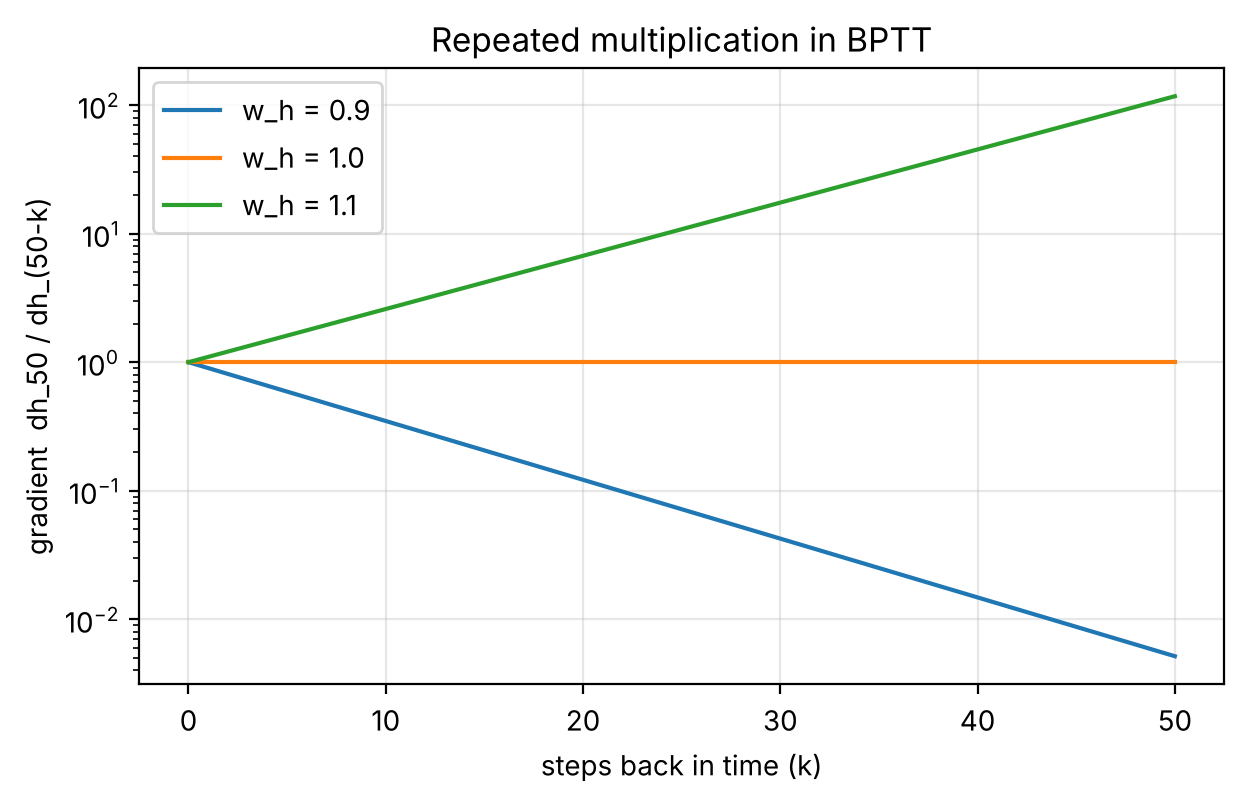

In [7]:
def grad_through_time(w_h, T=50):
    h = tf.zeros([1])                          # h0 = 0
    with tf.GradientTape() as tape:            # 계산 과정을 녹화
        tape.watch(h)
        hs = [h]
        for t in range(T):
            h = tf.tanh(w_h * h)               # 입력 x = 0
            hs.append(h)
    grads = tape.gradient(hs[-1], hs)          # h_T에서 거꾸로 역전파 (BPTT)
    return [float(g[0]) for g in grads]

plt.figure(figsize=(7, 4))
for w in [0.9, 1.0, 1.1]:
    g = grad_through_time(w)
    print(f"w_h = {w}:  50단계 거슬러 간 기울기 = {g[0]:.4g}")
    plt.semilogy(range(51)[::-1], g, label=f"w_h = {w}")
plt.xlabel("steps back in time (k)")
plt.ylabel("gradient  dh_50 / dh_(50-k)")
plt.legend(); plt.grid(alpha=0.3); plt.title("Repeated multiplication in BPTT")
plt.show()

**확인 4** 이론 슬라이드 15의 0.9⁵⁰ ≈ 0.005(소실), 1.1⁵⁰ ≈ 117(폭발)이 그대로 나오나요?

### 3-2. 실제 모델에서는? — ‘첫 단어 기억하기’ 과제

이론 슬라이드 16의 ‘프랑스 … ___어’ 문제를 단순하게 만든 과제입니다.

- 단어 0, 1은 **첫 자리에만** 나오는 단서이고, 단어 2~9는 뒤에 이어지는 방해 단어입니다.
- 모델은 끝까지 읽은 뒤 **첫 단어가 0이었는지 1이었는지** 맞혀야 합니다.
- 각 단어는 길이 10짜리 원-핫 벡터로 바꿔서 넣습니다.
- 예: `[1, 7, 3, 9, 2, …, 4]` → 정답 1

In [8]:
VOCAB = 10

def make_data(n, T, seed=0):
    rng = np.random.default_rng(seed)
    tokens = rng.integers(2, VOCAB, size=(n, T))   # 방해 단어 2~9
    y = rng.integers(0, 2, size=n)                 # 정답 0 또는 1
    tokens[:, 0] = y                               # 첫 자리에 단서
    x = np.eye(VOCAB, dtype="float32")[tokens]     # 원-핫 벡터: (개수, 길이, 10)
    return x, y

x, y = make_data(3, 12, seed=1)
for i in range(3):
    print(x[i].argmax(axis=1).tolist(), "→ 정답", y[i])

[1, 6, 8, 9, 2, 3, 8, 9, 3, 4, 8, 5] → 정답 1
[0, 8, 4, 5, 7, 6, 2, 2, 8, 8, 8, 6] → 정답 0
[1, 4, 5, 8, 2, 4, 2, 5, 9, 3, 5, 5] → 정답 1


In [9]:
def build_model(kind="RNN", forget_bias=None, hidden=32):
    """원-핫 단어 → SimpleRNN/LSTM/GRU → 마지막 시점의 h로 0/1 분류 (다대일)"""
    inputs = keras.Input(shape=(None, VOCAB))
    if kind == "RNN":
        rnn = layers.SimpleRNN(hidden)
    elif kind == "GRU":
        rnn = layers.GRU(hidden)               # [과제 A] 게이트 2개(업데이트 z, 리셋 r), 셀 상태 없이 h만 사용
    else:
        rnn = layers.LSTM(hidden)              # Keras 기본: 망각 게이트 편향 = 1
    outputs = layers.Dense(2)(rnn(inputs))
    model = keras.Model(inputs, outputs)
    if forget_bias is not None and kind == "LSTM":   # 망각 게이트는 LSTM에만 있음 (GRU bias 모양은 (2, 3*hidden)이라 그대로 쓰면 오류)
        b = rnn.cell.bias.numpy()              # Keras 게이트 순서: [입력 i, 망각 f, 후보 c, 출력 o]
        b[hidden:2 * hidden] = forget_bias
        rnn.cell.bias.assign(b)
    return model

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

학습하기 **전에**, 정답 기울기가 각 시점의 입력까지 얼마나 도착하는지 측정합니다. 문장 길이는 T = 100입니다.
비교할 모델은 세 가지입니다.

- 기본 RNN (`SimpleRNN`)
- 기본 LSTM (Keras 기본값: 망각 게이트 편향 1 → f ≈ σ(1) ≈ 0.73)
- LSTM + 망각 게이트 편향 2 (→ f ≈ σ(2) ≈ 0.88, 기억을 더 오래 유지하는 쪽으로 시작)

RNN              첫 단어까지 도착한 기울기 = 1.3e-06


LSTM (default)   첫 단어까지 도착한 기울기 = 7.9e-08


LSTM (f bias=2)  첫 단어까지 도착한 기울기 = 5.7e-02


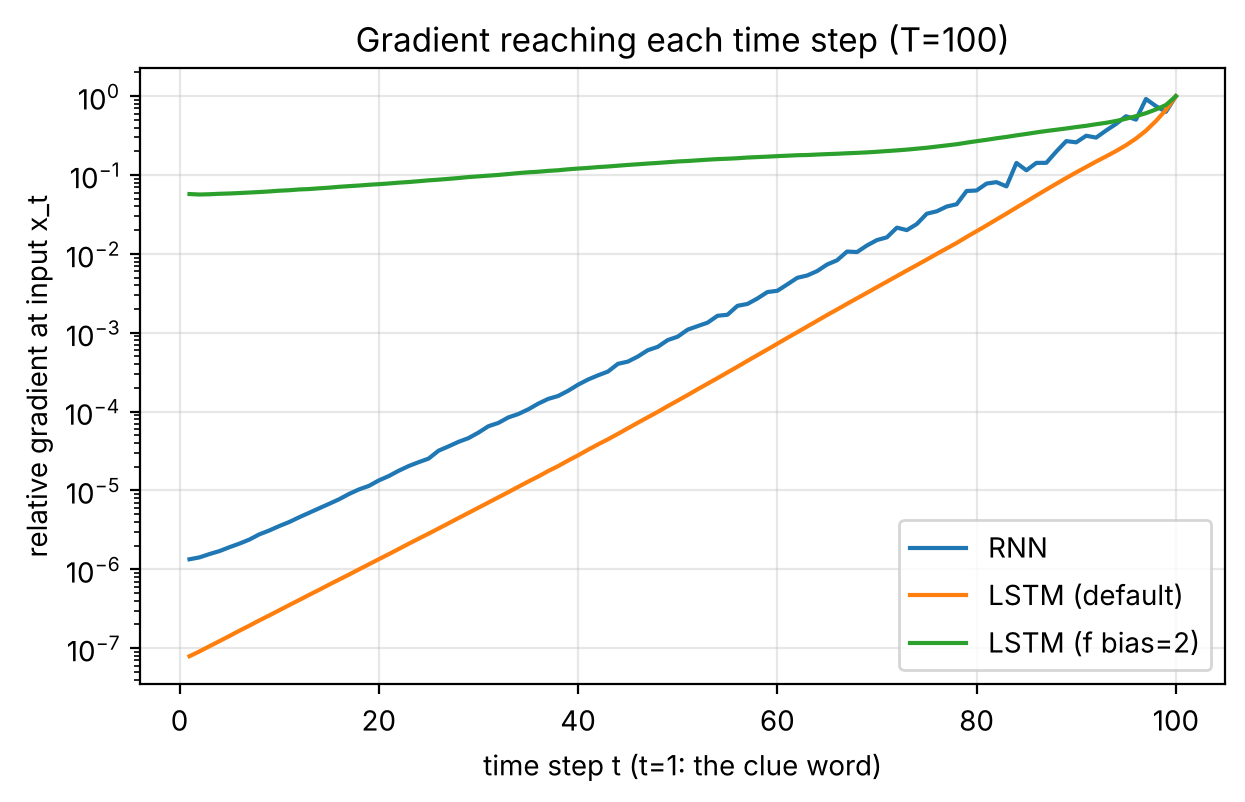

In [10]:
MODELS = {
    "RNN":             dict(kind="RNN"),
    "LSTM (default)":  dict(kind="LSTM"),
    "LSTM (f bias=2)": dict(kind="LSTM", forget_bias=2.0),
}

def gradient_profile(model, T=100):
    x, y = make_data(256, T, seed=0)
    x = tf.constant(x)
    with tf.GradientTape() as tape:
        tape.watch(x)                          # 각 시점의 입력을 지켜본다
        loss = loss_fn(y, model(x))
    g = tf.norm(tape.gradient(loss, x), axis=2)      # BPTT로 받은 시점별 기울기 크기
    g = tf.reduce_mean(g, axis=0).numpy()
    return g / g[-1]                                 # 마지막 시점 = 1로 맞춤

plt.figure(figsize=(7, 4))
for name, cfg in MODELS.items():
    keras.utils.set_random_seed(0)
    g = gradient_profile(build_model(**cfg))
    print(f"{name:16s} 첫 단어까지 도착한 기울기 = {g[0]:.1e}")
    plt.semilogy(range(1, 101), g, label=name)
plt.xlabel("time step t (t=1: the clue word)")
plt.ylabel("relative gradient at input x_t")
plt.legend(); plt.grid(alpha=0.3); plt.title("Gradient reaching each time step (T=100)")
plt.show()

**확인 5** 기본 RNN과 기본 LSTM에서 첫 단어(단서)에 도착하는 기울기는 마지막 시점의 100만분의 1 이하입니다.
망각 게이트가 1에 더 가까운 LSTM은 기울기가 훨씬 덜 줄어든 채 단서까지 도착합니다 → 이론 슬라이드 22.

## 실습 4. 직접 학습시켜 보기 (이론 슬라이드 17, 22)

짧은 문장(T = 10)과 긴 문장(T = 100)에서 세 모델을 각각 학습시킵니다(64개씩 500번).
옵티마이저의 `global_clipnorm=1.0`이 이론 슬라이드 17의 **기울기 클리핑**입니다.

In [11]:
def train(cfg, T, seed=0):
    keras.utils.set_random_seed(seed)
    model = build_model(**cfg)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=3e-3, global_clipnorm=1.0),  # 기울기 클리핑
        loss=loss_fn, metrics=["accuracy"])
    x, y = make_data(32000, T, seed)                     # 64개씩 500번 = 32,000문장
    model.fit(x, y, batch_size=64, epochs=1, verbose=0)  # 매 배치마다 BPTT
    x_test, y_test = make_data(1000, T, seed + 100)      # 처음 보는 문장으로 평가
    return model.evaluate(x_test, y_test, verbose=0)[1]

results = {}
for T in [10, 100]:
    for name, cfg in MODELS.items():
        results[(T, name)] = train(cfg, T)
        print(f"T = {T:3d} | {name:16s} | 정확도 {results[(T, name)]:.1%}")

T =  10 | RNN              | 정확도 100.0%


T =  10 | LSTM (default)   | 정확도 100.0%


T =  10 | LSTM (f bias=2)  | 정확도 100.0%


T = 100 | RNN              | 정확도 50.2%


T = 100 | LSTM (default)   | 정확도 52.4%


T = 100 | LSTM (f bias=2)  | 정확도 100.0%


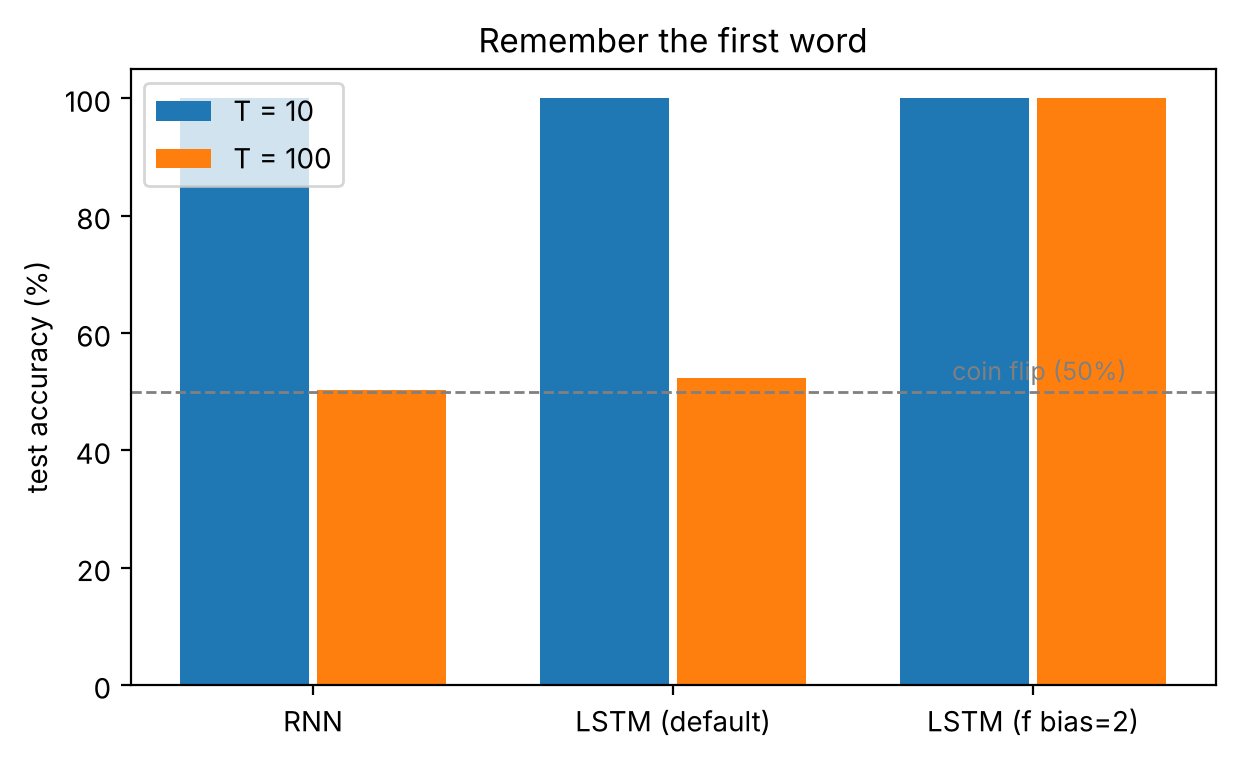

In [12]:
names = list(MODELS)
fig, ax = plt.subplots(figsize=(7, 4))
for i, T in enumerate([10, 100]):
    accs = [results[(T, n)] * 100 for n in names]
    ax.bar([j + i * 0.38 for j in range(3)], accs, width=0.36, label=f"T = {T}")
ax.axhline(50, ls="--", c="gray", lw=1); ax.text(2.45, 52, "coin flip (50%)", ha="right", fontsize=9, color="gray")
ax.set_xticks([j + 0.19 for j in range(3)]); ax.set_xticklabels(names)
ax.set_ylabel("test accuracy (%)"); ax.set_ylim(0, 105); ax.legend()
ax.set_title("Remember the first word")
plt.show()

**확인 6** 결과를 이론과 연결해 봅시다.

1. **T = 10**: 세 모델 모두 100% — 짧은 문장에서는 기본 RNN도 충분합니다.
2. **T = 100, 기본 RNN**: 50% 안팎(찍기 수준) — 단서까지 기울기가 거의 도착하지 않아 배우지 못합니다(장기의존성 문제).
3. **T = 100, 기본 LSTM**: 역시 50% 안팎 — f ≈ 0.73에서 시작하면 100단계를 건너는 동안 기억과 기울기가 거의 사라집니다.
4. **T = 100, LSTM(f 편향 2)**: 100% — f가 1에 가까울수록 셀 상태를 따라 기울기가 보존됩니다.

## 도전 과제 (영상 이후 직접 해 보기)

- `MODELS`에 `"GRU": dict(kind="GRU")`를 추가하려면 `build_model`에서 무엇을 고쳐야 할까요? 고친 뒤 같은 실험을 해 보세요.
- `forget_bias`를 0, 1, 2, 3으로 바꾸며 T = 100 정확도가 어떻게 달라지는지 표로 정리해 보세요.
- `train`의 `seed`를 1, 2로 바꿔 다시 실행해 보세요. 결과가 늘 같나요? 다르다면 이유는 무엇일까요?

---
# 도전 과제 풀이

## A. GRU 추가하기

In [13]:
MODELS_ALL = {**MODELS, "GRU": dict(kind="GRU")}

# (1) 학습 결과
for T in [10, 100]:
    acc = train(MODELS_ALL["GRU"], T)
    print(f"T = {T:3d} | GRU | 정확도 {acc:.1%}")

T =  10 | GRU | 정확도 100.0%


T = 100 | GRU | 정확도 52.6%


RNN              첫 단어까지 도착한 기울기 = 1.3e-06


LSTM (default)   첫 단어까지 도착한 기울기 = 7.9e-08


LSTM (f bias=2)  첫 단어까지 도착한 기울기 = 5.7e-02


GRU              첫 단어까지 도착한 기울기 = 0.0e+00


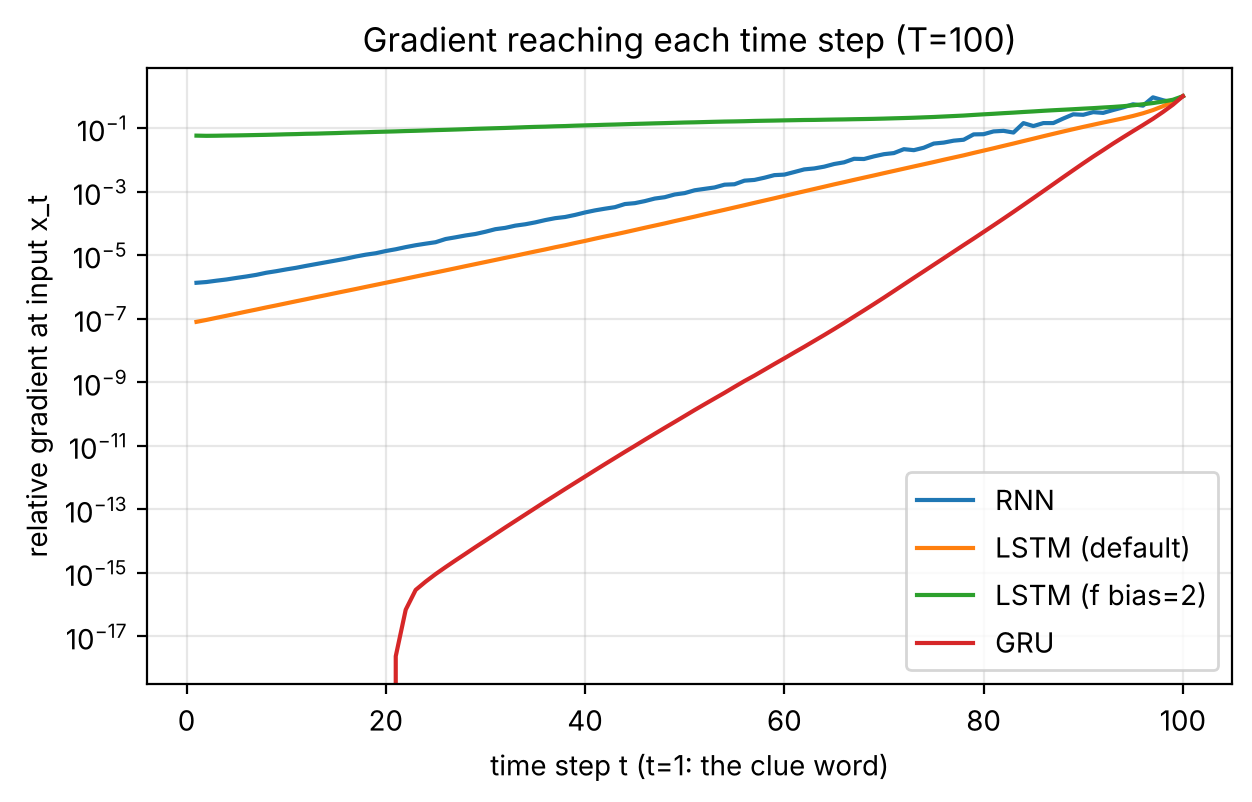

In [14]:
# (2) 학습 전 기울기 프로파일 (T = 100)
plt.figure(figsize=(7, 4))
for name, cfg in MODELS_ALL.items():
    keras.utils.set_random_seed(0)
    g = gradient_profile(build_model(**cfg))
    print(f"{name:16s} 첫 단어까지 도착한 기울기 = {g[0]:.1e}")
    plt.semilogy(range(1, 101), g, label=name)
plt.xlabel("time step t (t=1: the clue word)")
plt.ylabel("relative gradient at input x_t")
plt.legend(); plt.grid(alpha=0.3); plt.title("Gradient reaching each time step (T=100)")
plt.show()

## B. 망각 게이트 편향 바꾸기

In [15]:
import math

rows = []
for fb in [0.0, 1.0, 2.0, 3.0]:
    acc = train(dict(kind="LSTM", forget_bias=fb), 100)
    f0 = 1 / (1 + math.exp(-fb))
    rows.append((fb, f0, acc))
    print(f"forget_bias = {fb:.0f} (f ≈ {f0:.2f}) | T = 100 | 정확도 {acc:.1%}")

print()
print("| forget_bias | f ≈ σ(b) | 정확도 | 결과 |")
print("| --- | --- | --- | --- |")
for fb, f0, acc in rows:
    print(f"| {fb:.0f} | {f0:.2f} | {acc:.1%} | {'성공' if acc > 0.9 else '실패'} |")

forget_bias = 0 (f ≈ 0.50) | T = 100 | 정확도 53.1%


forget_bias = 1 (f ≈ 0.73) | T = 100 | 정확도 52.4%


forget_bias = 2 (f ≈ 0.88) | T = 100 | 정확도 100.0%


forget_bias = 3 (f ≈ 0.95) | T = 100 | 정확도 100.0%

| forget_bias | f ≈ σ(b) | 정확도 | 결과 |
| --- | --- | --- | --- |
| 0 | 0.50 | 53.1% | 실패 |
| 1 | 0.73 | 52.4% | 실패 |
| 2 | 0.88 | 100.0% | 성공 |
| 3 | 0.95 | 100.0% | 성공 |


## C. 시드 바꿔 보기

In [16]:
seed_results = {}
for seed in [0, 1, 2]:
    for name, cfg in MODELS_ALL.items():
        seed_results[(name, seed)] = train(cfg, 100, seed=seed)

print("| 모델 | seed 0 | seed 1 | seed 2 |")
print("| --- | --- | --- | --- |")
for name in MODELS_ALL:
    accs = " | ".join(f"{seed_results[(name, s)]:.1%}" for s in [0, 1, 2])
    print(f"| {name} | {accs} |")

| 모델 | seed 0 | seed 1 | seed 2 |
| --- | --- | --- | --- |
| RNN | 50.2% | 48.3% | 100.0% |
| LSTM (default) | 52.4% | 51.8% | 50.3% |
| LSTM (f bias=2) | 100.0% | 100.0% | 100.0% |
| GRU | 52.6% | 51.7% | 50.4% |


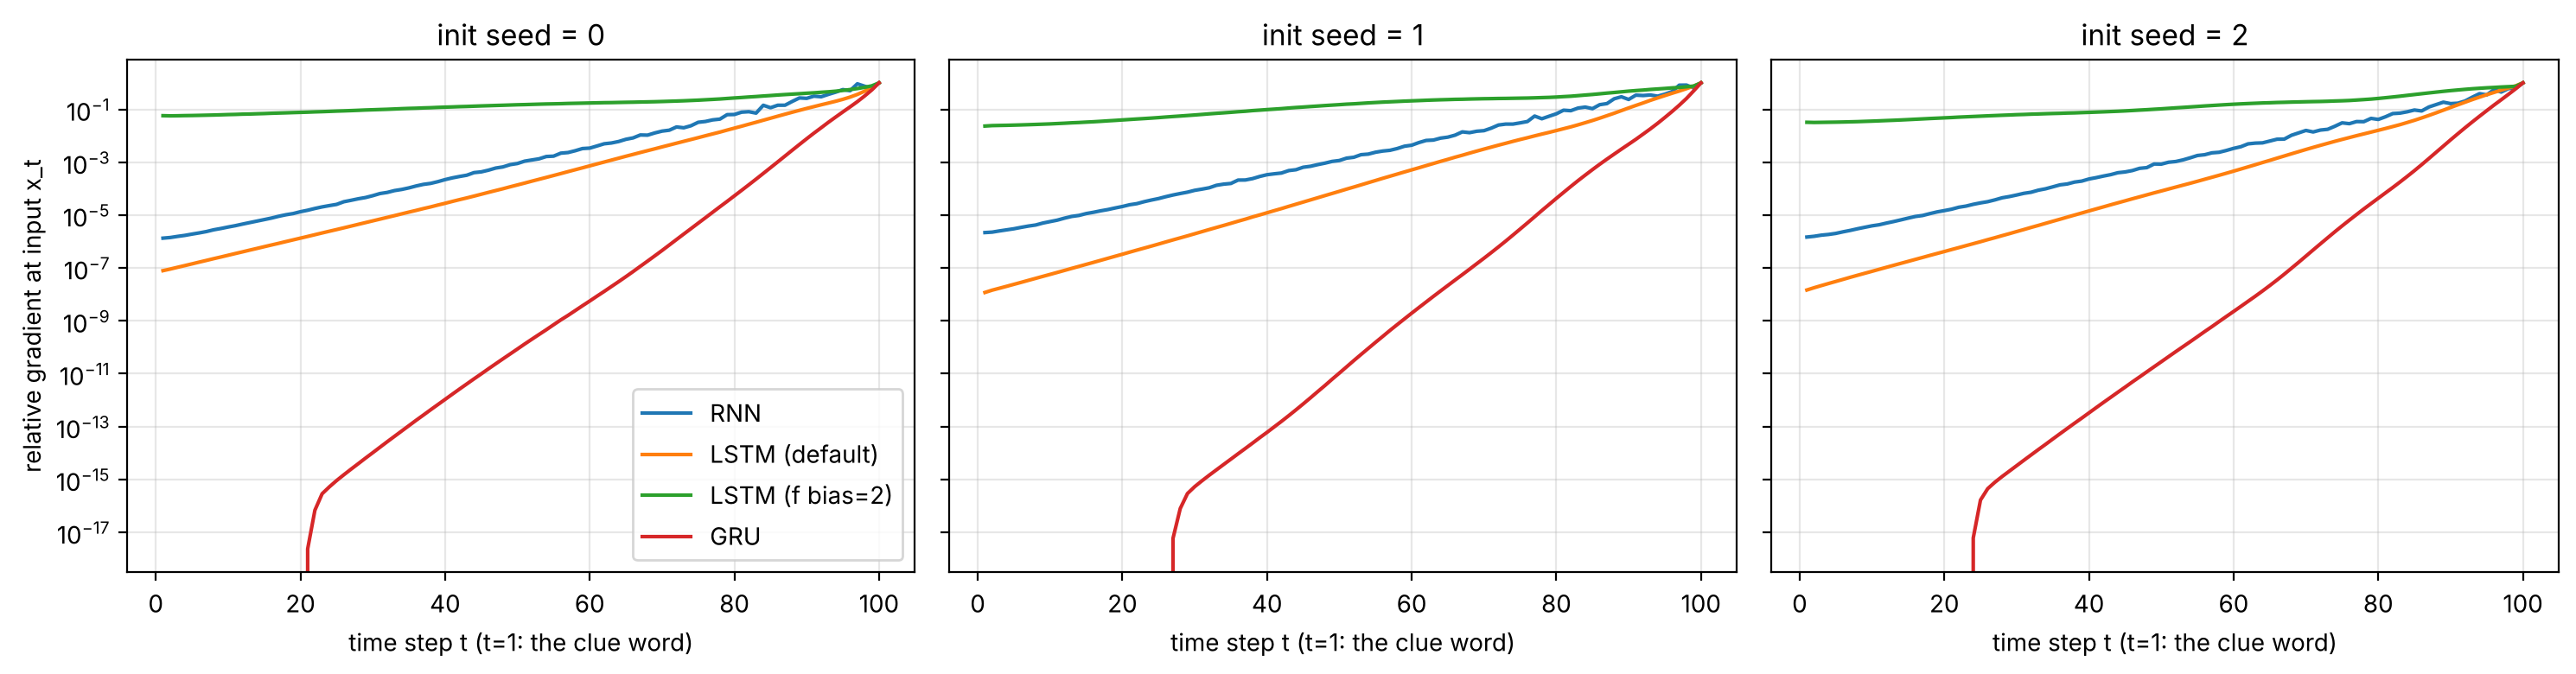

In [17]:
# 학습 전 기울기 프로파일을 초기화 시드별로 비교 (실습 3의 그래프)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, s in zip(axes, [0, 1, 2]):
    for name, cfg in MODELS_ALL.items():
        keras.utils.set_random_seed(s)
        g = gradient_profile(build_model(**cfg))
        ax.semilogy(range(1, 101), g, label=name)
    ax.set_title(f"init seed = {s}")
    ax.set_xlabel("time step t (t=1: the clue word)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("relative gradient at input x_t")
axes[0].legend()
plt.tight_layout()
plt.show()

**결과가 늘 같지는 않습니다.**

**이유**
- **LSTM (f 편향 2)**: 세 시드 모두 첫 단어까지 기울기가 약 1e-2~1e-1로 도착합니다. 구조가 기억 경로를 열어 두기 때문에 초기화가 바뀌어도 결과가 안정적이고, 정확도도 늘 100%입니다.
- **RNN, 기본 LSTM, GRU**: 첫 단어까지 오는 기울기가 1e-6 이하(GRU는 더 작음)입니다. 학습 성공 여부가 이 아주 작은 신호에 달려 있어서 결과가 거의 운에 가깝고, 대부분은 찍기 수준(50% 안팎)에 머뭅니다.